# LLM Math Reasoning Experiment with OpenAI-Compatible API on DS2

This notebook runs math-reasoning prompt experiments against an OpenAI v1-compatible chat completions API using `ds2.csv`.

**Setup:**
1. Place `ds2.csv` in the notebook directory, `/kaggle/working/`, or an attached Kaggle input dataset.
2. Provide a `.env` file or environment variables with:
   - `OPENAI_API_KEY`
   - `OPENAI_BASE_URL` or `OPENAI_URL`
   - optional `OPENAI_MODEL`
   - optional `DELAYS` in seconds between API calls

The notebook writes result files with `.math.ds2` in the output filename.


In [1]:
# No local model packages are required for the OpenAI-compatible API runner.


In [2]:
# No apt packages are required for the OpenAI-compatible API runner.


In [3]:
import os
import time
import requests
import json
import re
import csv
from datetime import datetime
from pathlib import Path


def load_env_file(path):
    """Small .env loader to avoid an extra dependency."""
    path = Path(path)
    if not path.exists():
        return False
    for raw_line in path.read_text(encoding="utf-8").splitlines():
        line = raw_line.strip()
        if not line or line.startswith("#") or "=" not in line:
            continue
        key, value = line.split("=", 1)
        key = key.strip()
        value = value.strip().strip('"').strip("'")
        os.environ.setdefault(key, value)
    return True


def load_env():
    """Load .env from common local/Kaggle locations without printing secrets."""
    candidate_paths = [
        Path(".env"),
        Path("/kaggle/working/.env"),
        Path("/kaggle/input/.env"),
    ]
    kaggle_input = Path(".")
    if kaggle_input.exists():
        candidate_paths.extend(kaggle_input.glob("**/.env"))

    loaded = []
    for path in candidate_paths:
        try:
            if load_env_file(path):
                loaded.append(str(path))
        except Exception as exc:
            print(f"Could not load {path}: {exc}")
    print(f"Loaded .env files: {loaded if loaded else 'none found; using existing environment variables'}")


load_env()

OPENAI_API_KEY = os.getenv("OPENAI_API_KEY")
OPENAI_BASE_URL = (
    os.getenv("OPENAI_BASE_URL")
    or os.getenv("OPENAI_URL")
    or os.getenv("OPENAI_API_BASE")
    or "https://api.openai.com/v1"
)
OPENAI_MODEL = os.getenv("OPENAI_MODEL", "gpt-4o-mini")
DELAYS = float(os.getenv("DELAYS", "0"))

if not OPENAI_API_KEY:
    raise ValueError("OPENAI_API_KEY is missing. Add it to .env or environment variables.")

print("OpenAI-compatible API configured.")
print(f"Base URL: {OPENAI_BASE_URL}")
print(f"Model: {OPENAI_MODEL}")
print(f"Delay between API calls: {DELAYS}s")


Loaded .env files: ['.env', '.env']
OpenAI-compatible API configured.
Base URL: https://openrouter.ai/api/v1
Model: inclusionai/ling-2.6-1t:free
Delay between API calls: 0.0s


In [4]:
# OpenAI-compatible API mode does not need a local server.


In [5]:
# Available models depend on your API provider and `OPENAI_MODEL` setting.


## 2. Math Configuration and Data Loading


In [6]:
def chat_completions_url(base_url: str) -> str:
    base_url = base_url.rstrip("/")
    if base_url.endswith("/chat/completions"):
        return base_url

    # Gemini's OpenAI-compatible endpoint is:
    # https://generativelanguage.googleapis.com/v1beta/openai/chat/completions
    if "generativelanguage.googleapis.com" in base_url:
        if base_url.endswith("/openai"):
            return f"{base_url}/chat/completions"
        if base_url.endswith("/v1beta") or base_url.endswith("/v1"):
            return f"{base_url}/openai/chat/completions"
        return f"{base_url}/chat/completions"

    if base_url.endswith("/v1"):
        return f"{base_url}/chat/completions"
    return f"{base_url}/v1/chat/completions"


def call_openai_v1(model, system_prompt, user_prompt):
    start = time.time()
    try:
        messages = []
        if system_prompt:
            messages.append({"role": "system", "content": system_prompt})
        messages.append({"role": "user", "content": user_prompt})

        payload = {
            "model": model,
            "messages": messages,
            "temperature": 0.2,
            "max_tokens": 2048,
        }
        headers = {
            "Authorization": f"Bearer {OPENAI_API_KEY}",
            "Content-Type": "application/json",
        }
        r = requests.post(
            chat_completions_url(OPENAI_BASE_URL),
            headers=headers,
            json=payload,
            timeout=300,
        )
        r.raise_for_status()
        data = r.json()
        usage = data.get("usage", {})
        response = data["choices"][0]["message"].get("content", "")
        return response, {
            "duration": time.time() - start,
            "prompt_tokens": usage.get("prompt_tokens", 0),
            "completion_tokens": usage.get("completion_tokens", 0),
            "success": True,
            "error": "",
            "raw_finish_reason": data["choices"][0].get("finish_reason", ""),
        }
    except Exception as e:
        return "", {
            "duration": time.time() - start,
            "prompt_tokens": 0,
            "completion_tokens": 0,
            "success": False,
            "error": str(e),
            "raw_finish_reason": "",
        }


def normalize_response_text(response: str) -> str:
    """Keep only the likely final answer from a model response."""
    text = response.strip()
    text = re.sub(r"```(?:text|json|python)?\s*", "", text, flags=re.IGNORECASE)
    text = text.replace("```", "").strip()
    marker_patterns = [
        r"(?:final answer|answer|result)\s*(?:is|:)?\s*(.+)$",
        r"(?:therefore|so),?\s*(.+)$",
    ]
    for pattern in marker_patterns:
        matches = re.findall(pattern, text, flags=re.IGNORECASE | re.DOTALL)
        if matches:
            text = matches[-1].strip()
            break
    lines = [line.strip() for line in text.splitlines() if line.strip()]
    if lines:
        text = lines[-1]
    return text.strip().strip(".")


def normalize_answer_text(text: str) -> str:
    text = normalize_response_text(str(text))
    text = text.lower()
    text = text.replace("\\times", "x").replace("×", "x")
    text = text.replace("\\cdot", "x").replace("·", "x")
    text = re.sub(r"\\text\{([^}]*)\}", r"\1", text)
    text = re.sub(r"[$`{}\\]", "", text)
    text = re.sub(r"\s+", " ", text).strip()
    text = re.sub(r"\s*,\s*", ",", text)
    return text


def extract_numbers(text: str):
    text = normalize_response_text(text)
    values = []
    for match in re.finditer(r"[-+]?\d+(?:\.\d+)?\s*%?", text):
        token = match.group(0).strip()
        is_percent = token.endswith("%")
        token = token.rstrip("%")
        try:
            value = float(token)
        except ValueError:
            continue
        if is_percent:
            value /= 100
        values.append(value)
    return values


def almost_equal(actual, expected, tolerance=1e-6):
    return abs(float(actual) - float(expected)) <= tolerance


def evaluate_ds2_answer(response_text: str, expected_answer: str, tolerance=1e-6):
    response_norm = normalize_answer_text(response_text)
    expected_norm = normalize_answer_text(expected_answer)
    errors = []

    # String containment handles units and expression answers better than numeric-only scoring.
    if response_norm == expected_norm or expected_norm in response_norm:
        return {
            "passed": True,
            "values_passed": 1,
            "values_total": 1,
            "extracted_values": extract_numbers(response_text),
            "normalized_response": response_norm,
            "normalized_expected": expected_norm,
            "errors": [],
        }

    expected_numbers = extract_numbers(expected_answer)
    response_numbers = extract_numbers(response_text)
    numeric_pass = False
    if expected_numbers and len(response_numbers) >= len(expected_numbers):
        candidate = response_numbers[-len(expected_numbers):]
        numeric_pass = all(almost_equal(a, e, tolerance) for a, e in zip(candidate, expected_numbers))
    else:
        candidate = response_numbers

    if numeric_pass:
        return {
            "passed": True,
            "values_passed": len(expected_numbers),
            "values_total": len(expected_numbers),
            "extracted_values": candidate,
            "normalized_response": response_norm,
            "normalized_expected": expected_norm,
            "errors": [],
        }

    errors.append(f"Expected {expected_answer!r}, got {normalize_response_text(response_text)!r}")
    return {
        "passed": False,
        "values_passed": 0,
        "values_total": max(1, len(expected_numbers)),
        "extracted_values": response_numbers,
        "normalized_response": response_norm,
        "normalized_expected": expected_norm,
        "errors": errors,
    }


def build_ds2_prompt(row):
    prompt = str(row["problem_markdown"]).strip()
    return f"{prompt}\n\nWith the given information, what is the final answer?"


def parse_csv_row(row):
    return {
        "task_id": str(row["id"]),
        "description": build_ds2_prompt(row),
        "expected_answer": str(row.get("final_answer", "")).strip(),
        "country": row.get("country", ""),
        "competition": row.get("competition", ""),
        "topics_flat": row.get("topics_flat", ""),
        "language": row.get("language", ""),
        "problem_type": row.get("problem_type", ""),
    }


def get_completed_ids(filename):
    if not os.path.exists(filename):
        return set()
    completed = set()
    with open(filename, "r", encoding="utf-8") as f:
        for line in f:
            try:
                data = json.loads(line)
                completed.add(data.get("task_id"))
            except Exception:
                continue
    return completed


def append_result(filename, result):
    with open(filename, "a", encoding="utf-8") as f:
        f.write(json.dumps(result, ensure_ascii=False) + "\n")


def find_ds2_csv():
    candidates = [
        Path("ds2.csv"),
        Path("/kaggle/working/ds2.csv"),
        Path("/kaggle/input/ds2.csv"),
    ]
    kaggle_input = Path("/kaggle/input")
    if kaggle_input.exists():
        candidates.extend(kaggle_input.glob("**/ds2.csv"))
    for candidate in candidates:
        if candidate.exists():
            return str(candidate)
    return "ds2.csv"


csv_path = find_ds2_csv()
print(f"Using DS2 CSV: {csv_path}")


Using DS2 CSV: ds2.csv


In [7]:
model_choice = OPENAI_MODEL
start_problem = 1
end_problem = 372
system_prompt = "Return only the final math answer. Do not write code."

safe_model_name = re.sub(r"[^A-Za-z0-9_.-]+", "-", model_choice).strip("-")
output_filename = f"./results/{safe_model_name}_{start_problem}_{end_problem}.math.ds2.jsonl"
completed_ids = get_completed_ids(output_filename)

problems_to_test = []
with open(csv_path, "r", encoding="utf-8") as f:
    reader = csv.DictReader(f)
    for row_number, row in enumerate(reader, start=1):
        if start_problem <= row_number <= end_problem:
            prob = parse_csv_row(row)
            if prob["task_id"] not in completed_ids:
                prob["row_number"] = row_number
                problems_to_test.append(prob)

print(f"Loaded {len(problems_to_test)} remaining DS2 math tasks for rows {start_problem}-{end_problem}.")

for index, prob in enumerate(problems_to_test):
    if index > 0 and DELAYS > 0:
        time.sleep(DELAYS)
    print(f"Testing row {prob['row_number']} / {prob['task_id']}...", end=" ", flush=True)
    response_text, meta = call_openai_v1(model_choice, system_prompt, prob["description"])
    if not meta["success"]:
        print(f"Error: {meta['error']}")
        result = {
            "timestamp": datetime.now().isoformat(),
            "model": model_choice,
            "task_id": prob["task_id"],
            "row_number": prob["row_number"],
            "passed": False,
            "values_passed": 0,
            "values_total": 1,
            "expected_answer": prob["expected_answer"],
            "extracted_values": [],
            "normalized_response": "",
            "normalized_expected": normalize_answer_text(prob["expected_answer"]),
            "errors": [meta["error"]],
            "duration_seconds": meta["duration"],
            "prompt_tokens": meta["prompt_tokens"],
            "completion_tokens": meta["completion_tokens"],
            "finish_reason": meta.get("raw_finish_reason", ""),
            "response_text": response_text,
            "country": prob["country"],
            "competition": prob["competition"],
            "topics_flat": prob["topics_flat"],
            "language": prob["language"],
            "problem_type": prob["problem_type"],
        }
        append_result(output_filename, result)
        continue

    eval_res = evaluate_ds2_answer(response_text, prob["expected_answer"])
    print(f"{'PASS' if eval_res['passed'] else 'FAIL'} ({eval_res['values_passed']}/{eval_res['values_total']})")

    result = {
        "timestamp": datetime.now().isoformat(),
        "model": model_choice,
        "task_id": prob["task_id"],
        "row_number": prob["row_number"],
        "passed": eval_res["passed"],
        "values_passed": eval_res["values_passed"],
        "values_total": eval_res["values_total"],
        "expected_answer": prob["expected_answer"],
        "extracted_values": eval_res["extracted_values"],
        "normalized_response": eval_res["normalized_response"],
        "normalized_expected": eval_res["normalized_expected"],
        "errors": eval_res["errors"],
        "duration_seconds": meta["duration"],
        "prompt_tokens": meta["prompt_tokens"],
        "completion_tokens": meta["completion_tokens"],
        "finish_reason": meta.get("raw_finish_reason", ""),
        "response_text": response_text,
        "country": prob["country"],
        "competition": prob["competition"],
        "topics_flat": prob["topics_flat"],
        "language": prob["language"],
        "problem_type": prob["problem_type"],
    }
    append_result(output_filename, result)

print(f"Results saved to {output_filename}")


Loaded 144 remaining DS2 math tasks for rows 1-372.
Testing row 1 / 04bo... FAIL (0/3)
Testing row 2 / 0cx2... FAIL (0/9)
Testing row 3 / 08x7... FAIL (0/1)
Testing row 4 / 03s6... FAIL (0/4)
Testing row 5 / 04ps... PASS (1/1)
Testing row 6 / 0epn... PASS (1/1)
Testing row 7 / 02f7... FAIL (0/13)
Testing row 8 / 0esj... PASS (1/1)
Testing row 9 / 0gxa... FAIL (0/2)
Testing row 10 / 09v0... PASS (1/1)
Testing row 11 / 0esc... PASS (1/1)
Testing row 12 / 049f... PASS (1/1)
Testing row 13 / 0h78... FAIL (0/2)
Testing row 14 / 09ni... FAIL (0/1)
Testing row 15 / 04pf... PASS (1/1)
Testing row 16 / 0ert... PASS (1/1)
Testing row 17 / 03xe... PASS (2/2)
Testing row 18 / 040y... FAIL (0/2)
Testing row 19 / 0a12... PASS (3/3)
Testing row 20 / 03ri... FAIL (0/1)
Testing row 21 / 0ep6... PASS (1/1)
Testing row 22 / 09zp... PASS (1/1)
Testing row 23 / 06j7... PASS (1/1)
Testing row 24 / 0ep1... FAIL (0/1)
Testing row 25 / 09kk... FAIL (0/1)
Testing row 26 / 08sf... FAIL (0/1)
Testing row 27 / 09m

In [18]:
from collections import OrderedDict

def load_429_task_ids(results_file):
    task_ids = []
    if not Path(results_file).exists():
        print(f"No results file found: {results_file}")
        return task_ids

    with open(results_file, "r", encoding="utf-8") as f:
        for line in f:
            try:
                data = json.loads(line)
            except Exception:
                continue

            errors = data.get("errors", [])
            if isinstance(errors, str):
                errors = [errors]

            if any("429 Client Error" in str(err) for err in errors):
                task_ids.append(str(data.get("task_id", "")))

    # keep order, remove duplicates
    return list(OrderedDict.fromkeys(tid for tid in task_ids if tid))


def load_rows_by_task_id(csv_file):
    rows = {}
    with open(csv_file, "r", encoding="utf-8") as f:
        reader = csv.DictReader(f)
        for row_number, row in enumerate(reader, start=1):
            prob = parse_csv_row(row)
            prob["row_number"] = row_number
            rows[prob["task_id"]] = prob
    return rows


retry_task_ids = load_429_task_ids(output_filename)
rows_by_task_id = load_rows_by_task_id(csv_path)

retry_probs = [rows_by_task_id[task_id] for task_id in retry_task_ids if task_id in rows_by_task_id]

print(f"Found {len(retry_probs)} tasks to rerun due to 429 errors.")

for i, prob in enumerate(retry_probs):
    if i > 0 and DELAYS > 0:
        time.sleep(DELAYS)

    print(f"Retrying row {prob['row_number']} / {prob['task_id']}...", end=" ", flush=True)
    response_text, meta = call_openai_v1(model_choice, system_prompt, prob["description"])

    if not meta["success"]:
        print(f"Error: {meta['error']}")
        result = {
            "timestamp": datetime.now().isoformat(),
            "model": model_choice,
            "task_id": prob["task_id"],
            "row_number": prob["row_number"],
            "passed": False,
            "values_passed": 0,
            "values_total": 1,
            "expected_answer": prob["expected_answer"],
            "extracted_values": [],
            "normalized_response": "",
            "normalized_expected": normalize_answer_text(prob["expected_answer"]),
            "errors": [meta["error"]],
            "duration_seconds": meta["duration"],
            "prompt_tokens": meta["prompt_tokens"],
            "completion_tokens": meta["completion_tokens"],
            "finish_reason": meta.get("raw_finish_reason", ""),
            "response_text": response_text,
            "country": prob["country"],
            "competition": prob["competition"],
            "topics_flat": prob["topics_flat"],
            "language": prob["language"],
            "problem_type": prob["problem_type"],
            "rerun_reason": "429 retry",
        }
        append_result(output_filename, result)
        continue

    eval_res = evaluate_ds2_answer(response_text, prob["expected_answer"])
    print(f"{'PASS' if eval_res['passed'] else 'FAIL'} ({eval_res['values_passed']}/{eval_res['values_total']})")

    result = {
        "timestamp": datetime.now().isoformat(),
        "model": model_choice,
        "task_id": prob["task_id"],
        "row_number": prob["row_number"],
        "passed": eval_res["passed"],
        "values_passed": eval_res["values_passed"],
        "values_total": eval_res["values_total"],
        "expected_answer": prob["expected_answer"],
        "extracted_values": eval_res["extracted_values"],
        "normalized_response": eval_res["normalized_response"],
        "normalized_expected": eval_res["normalized_expected"],
        "errors": eval_res["errors"],
        "duration_seconds": meta["duration"],
        "prompt_tokens": meta["prompt_tokens"],
        "completion_tokens": meta["completion_tokens"],
        "finish_reason": meta.get("raw_finish_reason", ""),
        "response_text": response_text,
        "country": prob["country"],
        "competition": prob["competition"],
        "topics_flat": prob["topics_flat"],
        "language": prob["language"],
        "problem_type": prob["problem_type"],
        "rerun_reason": "429 retry",
    }
    append_result(output_filename, result)

print(f"Retry run complete. Results appended to {output_filename}")

Found 94 tasks to rerun due to 429 errors.
Retrying row 51 / 03rj... Rate limited (429). Retrying in 1.0s...
Rate limited (429). Retrying in 2.0s...
Rate limited (429). Retrying in 4.0s...
Rate limited (429). Retrying in 8.0s...


KeyboardInterrupt: 

Completed-id filter updated: error rows will be rerun.


In [8]:
response_text

''

In [9]:
# gemini-3.1-flash-lite-preview_1_372.math.ds2.jsonl

Rows: 144
Pass rate: 14.58%
Avg duration: 2.51s
Median duration: 0.29s


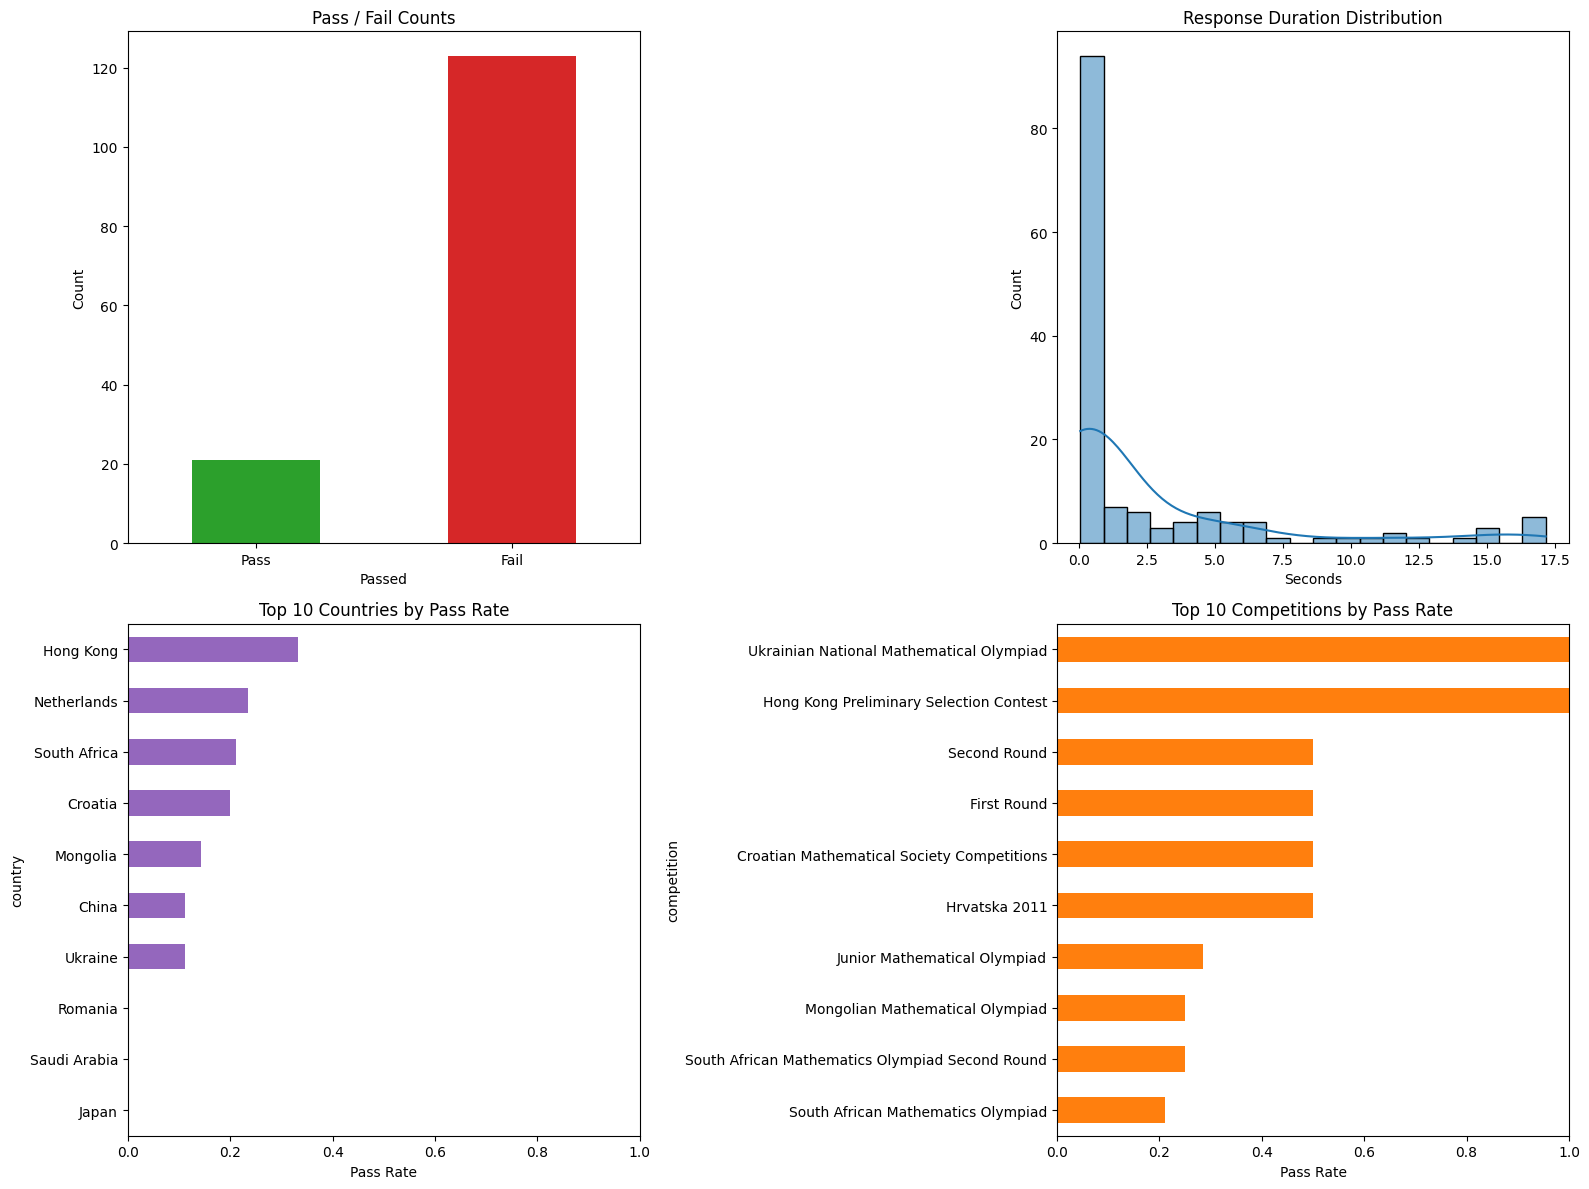


Average metrics by pass/fail:
        duration_seconds  prompt_tokens  completion_tokens  token_total
passed                                                                 
False           2.033028      25.878049         227.268293   253.146341
True            5.283813     105.952381         603.428571   709.380952


In [10]:
import pandas as pd
import seaborn as sns

import matplotlib.pyplot as plt

results_path = output_filename
df = pd.read_json(results_path, lines=True)

df["duration_seconds"] = pd.to_numeric(df["duration_seconds"], errors="coerce")
df["passed"] = df["passed"].fillna(False)

overall_pass_rate = df["passed"].mean()
print(f"Rows: {len(df)}")
print(f"Pass rate: {overall_pass_rate:.2%}")
print(f"Avg duration: {df['duration_seconds'].mean():.2f}s")
print(f"Median duration: {df['duration_seconds'].median():.2f}s")

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Pass / fail
df["passed"].value_counts().reindex([True, False]).plot(
    kind="bar", ax=axes[0, 0], color=["#2ca02c", "#d62728"]
)
axes[0, 0].set_title("Pass / Fail Counts")
axes[0, 0].set_xlabel("Passed")
axes[0, 0].set_ylabel("Count")
axes[0, 0].set_xticklabels(["Pass", "Fail"], rotation=0)

# Duration distribution
sns.histplot(df["duration_seconds"].dropna(), bins=20, kde=True, ax=axes[0, 1], color="#1f77b4")
axes[0, 1].set_title("Response Duration Distribution")
axes[0, 1].set_xlabel("Seconds")

# Pass rate by country
country_pass = (
    df.groupby("country")["passed"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)
country_pass.sort_values().plot(kind="barh", ax=axes[1, 0], color="#9467bd")
axes[1, 0].set_title("Top 10 Countries by Pass Rate")
axes[1, 0].set_xlabel("Pass Rate")
axes[1, 0].set_xlim(0, 1)

# Pass rate by competition
comp_pass = (
    df.groupby("competition")["passed"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)
comp_pass.sort_values().plot(kind="barh", ax=axes[1, 1], color="#ff7f0e")
axes[1, 1].set_title("Top 10 Competitions by Pass Rate")
axes[1, 1].set_xlabel("Pass Rate")
axes[1, 1].set_xlim(0, 1)

plt.tight_layout()
plt.show()

summary = (
    df.assign(token_total=df["prompt_tokens"].fillna(0) + df["completion_tokens"].fillna(0))
      .groupby("passed")[["duration_seconds", "prompt_tokens", "completion_tokens", "token_total"]]
      .mean()
)
print("\nAverage metrics by pass/fail:")
print(summary)

In [11]:
passed_count = int(df["passed"].fillna(False).sum())
total_count = len(df)

print(f"{passed_count} problems passed out of {total_count}.")

21 problems passed out of 144.


In [12]:
from pathlib import Path

# candidate paths for the Gemini results file
gemini_candidates = [
    Path("./results/gemini-3.1-flash-lite-preview_1_372.math.ds2.jsonl"),
    Path("gemini-3.1-flash-lite-preview_1_372.math.ds2.jsonl"),
    Path("/Users/macos/LearningSpace/ue-courses/Thesis/02ScalingPhrase/apimodel/results/gemini-3.1-flash-lite-preview_1_372.math.ds2.jsonl"),
]

gemini_path = next((p for p in gemini_candidates if p.exists()), None)
if gemini_path is None:
    raise FileNotFoundError("Could not find gemini results JSONL. Checked: " + ", ".join(str(p) for p in gemini_candidates))

# deepseek file (existing variable in the notebook)
deepseek_path = Path(output_filename) if 'output_filename' in globals() else Path("./results/deepseek-v4-flash_1_372.math.ds2.jsonl")
if not deepseek_path.exists():
    raise FileNotFoundError(f"Deepseek results file not found: {deepseek_path}")

# load JSONL into DataFrames
gem_df = pd.read_json(gemini_path, lines=True)
deep_df = pd.read_json(deepseek_path, lines=True)

# keep one record per task_id (last occurrence)
gem_unique = gem_df.sort_values("row_number").drop_duplicates("task_id", keep="last").set_index("task_id")
deep_unique = deep_df.sort_values("row_number").drop_duplicates("task_id", keep="last").set_index("task_id")

# outer join on task_id
combined = pd.DataFrame(index=sorted(set(gem_unique.index) | set(deep_unique.index)))
combined["gem_passed"] = gem_unique.reindex(combined.index)["passed"].fillna(False)
combined["deep_passed"] = deep_unique.reindex(combined.index)["passed"].fillna(False)

both = int(((combined["gem_passed"]) & (combined["deep_passed"])).sum())
only_deep = int(((combined["deep_passed"]) & (~combined["gem_passed"])).sum())
only_gemini = int(((combined["gem_passed"]) & (~combined["deep_passed"])).sum())
none = int((~combined["gem_passed"] & ~combined["deep_passed"]).sum())

print(f"Total distinct tasks compared: {len(combined)}")
print(f"Solved by both models: {both}")
print(f"Solved only by deepseek-v4-flash: {only_deep}")
print(f"Solved only by gemini-3.1-flash-lite-preview: {only_gemini}")
print(f"Not solved by either model: {none}")

# optional: show a small sample of task_ids in each category
print("\nSample task_ids (both):", combined[(combined["gem_passed"]) & (combined["deep_passed"])].index.tolist()[:10])
print("Sample task_ids (only deep):", combined[(combined["deep_passed"]) & (~combined["gem_passed"])].index.tolist()[:10])
print("Sample task_ids (only gemini):", combined[(combined["gem_passed"]) & (~combined["deep_passed"])].index.tolist()[:10])
print("Sample task_ids (none):", combined[(~combined["gem_passed"]) & (~combined["deep_passed"])].index.tolist()[:10])

Total distinct tasks compared: 144
Solved by both models: 11
Solved only by deepseek-v4-flash: 10
Solved only by gemini-3.1-flash-lite-preview: 23
Not solved by either model: 100

Sample task_ids (both): ['03xe', '049f', '04pf', '09v0', '09wb', '0ep6', '0epb', '0epn', '0eql', '0esc']
Sample task_ids (only deep): ['03w0', '03x9', '04ps', '06j7', '09mg', '09zp', '0a12', '0eq0', '0ert', '0h4k']
Sample task_ids (only gemini): ['03tj', '04c7', '08r3', '08zv', '09ni', '09xx', '0a18', '0a1d', '0eo9', '0eoc']
Sample task_ids (none): ['00dt', '00lr', '01e3', '01uq', '01w8', '02f7', '02of', '03og', '03or', '03p2']


## 4. Run Additional Ranges
Edit `start_problem`, `end_problem`, or `.env` `OPENAI_MODEL`, then rerun the final cell to process new DS2 math tasks. Output files use `.math.ds2.jsonl`.
